# Structure elucidation from ¹H NMR

Generate candidate molecular structures from NMR peak lists and a molecular formula.

The NMRTransformer spectral encoder represents the peak lists, and the molecular decoder generates SMILES with beam search. Candidates include their molecular formula agreement and decoding scores.

This tutorial loads the saved predictions, explains the input/output fields and evaluates the results. Use the final command to run the model on a new dataset.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.generation.h')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.generation.h
Examples: 3


## Inputs and outputs

| Field | Meaning |
| --- | --- |
| `h_nmr / c_nmr` | H records: shift positions (ppm), multiplicity/integration/J where recorded; obey the modality mask. |
| `formula` | A known molecular formula is required by this checkpoint. |
| `beam_size` | Number of decoded candidates; 5 in the documented experiment. |

| Field | Meaning |
| --- | --- |
| `candidates` | Generated SMILES, canonical structures, validity, formula match and model score. |
| `exact_match` | Canonical structural agreement with the reference molecule. |

Inspect the example records below. Long arrays show their length and first values; the downloadable JSON contains the complete arrays.

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "formula": "C22H28",
    "h_nmr": [
      {
        "type": "1H NMR",
        "chemical_shift": "7.34 (s, 4H), 7.265 (m, 2H), 7.165 (m, 3H), 5.26 (d, J=1.6 Hz, 1H), 5.01 (t, J=1.4 Hz, 1H), 2.61 (t, J=7.8 Hz, 2H), 2.53 (t, J=7.6 Hz, 2H), 1.665 (m, 2H), 1.52 (d, J=7.7 Hz, 2H), 1.33 (s, 9H)"
      }
    ],
    "c_nmr": [],
    "modality_mask": [
      1,
      0
    ]
  },
  "reference_smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
  "candidates": [
    {
      "smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
      "canonical_smiles": "C=C(CCCCc1ccccc1)c1ccc(C(C)(C)C)cc1",
      "score": -2.1940921595343212,
      "valid": true,
      "formula_match": true
    },
    {
      "smiles": "C=C(CCCCc1ccccc1)CCCc1ccccc1",
      "canonical_smiles": "C=C(CCCCc1ccccc1)CCCc1ccccc1",
      "score": -1.869783622449546,
      "valid": true,
      "formula_match": false
    },
    {
      "smiles": "C=C(CCCCc1ccccc1)C(=C)CCc1ccccc1",
      "canonical_smiles": "C=C(CCCCc1ccccc1)C(=C)

## Evaluate the predictions

Canonical top-k accuracy and valid-SMILES rate summarize generation.

The table gives the dataset and metric for each run. The following calculation recomputes summary values from the plotted predictions.

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| nmrspec_test | recorded model | modality | available |
| nmrspec_test | recorded model | examples | 32 |
| nmrspec_test | recorded model | skipped_missing_modality | 0 |
| nmrspec_test | recorded model | valid | 32 |
| nmrspec_test | recorded model | formula_match | 27 |
| nmrspec_test | recorded model | exact | 3 |
| nmrspec_test | recorded model | valid_rate | 1 |
| nmrspec_test | recorded model | formula_match_rate | 0.84375 |
| nmrspec_test | recorded model | exact_rate | 0.09375 |
| patent_test_10k | recorded model | modality | available |
| patent_test_10k | recorded model | examples | 32 |
| patent_test_10k | recorded model | skipped_missing_modality | 0 |
| patent_test_10k | recorded model | valid | 23 |
| patent_test_10k | recorded model | formula_match | 5 |
| patent_test_10k | recorded model | exact | 0 |
| patent_test_10k | recorded model | valid_rate | 0.71875 |
| patent_test_10k | recorded model | formula_match_rate | 0.15625 |
| patent_test_10k | recorded model | exact_rate | 0 |
| nmrexp_exp_10k | recorded model | modality | available |
| nmrexp_exp_10k | recorded model | examples | 32 |
| nmrexp_exp_10k | recorded model | skipped_missing_modality | 0 |
| nmrexp_exp_10k | recorded model | valid | 32 |
| nmrexp_exp_10k | recorded model | formula_match | 27 |
| nmrexp_exp_10k | recorded model | exact | 15 |
| nmrexp_exp_10k | recorded model | valid_rate | 1 |
| nmrexp_exp_10k | recorded model | formula_match_rate | 0.84375 |
| nmrexp_exp_10k | recorded model | exact_rate | 0.46875 |
| nmrgym_test | recorded model | modality | available |
| nmrgym_test | recorded model | examples | 32 |
| nmrgym_test | recorded model | skipped_missing_modality | 0 |
| nmrgym_test | recorded model | valid | 30 |
| nmrgym_test | recorded model | formula_match | 15 |
| nmrgym_test | recorded model | exact | 0 |
| nmrgym_test | recorded model | valid_rate | 0.9375 |
| nmrgym_test | recorded model | formula_match_rate | 0.46875 |
| nmrgym_test | recorded model | exact_rate | 0 |


{
  "top1_matches_reference_this_example": true
}


## Visualize the result

Reference structure and generated candidates.

Compare the prediction with the reference and inspect the returned structures or peak positions. The plot is generated directly from the records loaded above.

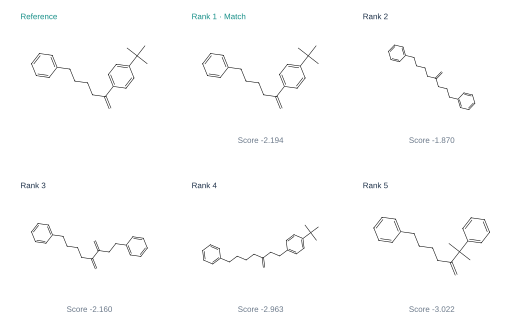

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.generation.h', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## Run the model

Configure the runtime and weights following the task guide. Select this task in the benchmark runner to evaluate your dataset.

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.generation.h --limit 8 --output results/nmr-generation-h.json
```

[Task](../tasks/nmr-generation-h.md) · [Quick start](../quickstart.md)



## References

- Yang, L., Yang, Z., Xie, J., Wang, Y., Gao, B., Fu, T., Wei, X., Sun, J., Wu, J., He, C., Li, Y. & Gu, Q. NMRTrans: Structure Elucidation from Experimental NMR Spectra via Set Transformers. arXiv:2602.10158 (2026). [Source](https://arxiv.org/abs/2602.10158)
- Fang, Z., Yang, C., Yu, H., Luo, H., He, H., Xie, J., Yang, Z. & Xia, J. NMRGym: A Comprehensive Benchmark for Nuclear Magnetic Resonance Based Molecular Structure Elucidation. arXiv:2601.15763 (2026). [Source](https://arxiv.org/abs/2601.15763)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
